Анализ данных собранных из Globus, Optobaza и Kampa.

In [10]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from dotenv import load_dotenv
from IPython.display import display

load_dotenv()
OUT = Path('eda_results'); OUT.mkdir(exist_ok=True)
url = URL.create('postgresql+psycopg', username=os.getenv('DB_USER','postgres'), password=os.getenv('DB_PASSWORD'), host=os.getenv('DB_HOST','localhost'), port=int(os.getenv('DB_PORT','5432')), database=os.getenv('DB_NAME','grocery_store'))
engine = create_engine(url)
with engine.connect() as c:
    print('База:', c.execute(text('SELECT current_database()')).scalar())


База: grocery_store



История цен на товар. Для анализа актуальных цен 

In [2]:
products = pd.read_sql("""SELECT p.*, s.name AS store_name FROM grocery_clean.products_clean p LEFT JOIN public.stores s ON s.id = p.store_id""", engine)
prices = pd.read_sql("""SELECT * FROM grocery_clean.price_history_clean""", engine)
raw_products = pd.read_sql('SELECT id, store_id, name FROM public.products', engine)
raw_prices = pd.read_sql('SELECT id, product_id, price_som, collected_at FROM public.price_history', engine)
print('Очищенные товары:',len(products),'| очищенные записи цен:',len(prices))
print('Исходные товары:',len(raw_products),'| исходные записи цен:',len(raw_prices))
prices['collected_at'] = pd.to_datetime(prices['collected_at'], utc=True, errors='coerce')
latest = (prices.sort_values(['collected_at','history_id'], na_position='first')
          .drop_duplicates('product_id',keep='last'))
df = products.merge(latest[['product_id','price_som','old_price_som','collected_at','price_per_unit','eligible_price','source_status']],on='product_id',how='left',validate='one_to_one')
display(df.head())


Очищенные товары: 6437 | очищенные записи цен: 8991
Исходные товары: 6437 | исходные записи цен: 11953


,product_id,store_id,original_name,name_clean,brand,category,total_quantity,normalized_unit,pack_count,attributes,...,review_reasons,rules_version,processed_at,store_name,price_som,old_price_som,collected_at,price_per_unit,eligible_price,source_status
0,1,1,Котле­ты Атахан говяди­на 1кг 1 шт.,котлеты атахан говядина 1кг 1 шт.,Атахан,Мясные полуфабрикаты,1.00,кг,1,{'product_scope': 'food'},...,,1.2,2026-11-13 12:19:44.577816+00:00,Globus,567.00,NaN,2026-11-06 15:22:35+00:00,567.00,True,public_page
1,2,1,Бифштекс рублен­ный Риха из говяди­ны 1кг 1 шт.,бифштекс рубленный риха из говядины 1кг 1 шт.,Риха,Мясные полуфабрикаты,1.00,кг,1,{'product_scope': 'food'},...,,1.2,2026-11-13 12:19:44.577816+00:00,Globus,852.00,NaN,2026-11-06 15:22:35+00:00,852.00,True,public_page
2,3,1,Котле­ты Риха куриные 1кг 1 шт.,котлеты риха куриные 1кг 1 шт.,Риха,Мясные полуфабрикаты,1.00,кг,1,{'product_scope': 'food'},...,,1.2,2026-11-13 12:19:44.577816+00:00,Globus,518.48,653.0,2026-11-06 15:22:35+00:00,518.48,True,public_page
3,4,1,Котле­ты Баркад 350 г 1 шт.,котлеты баркад 350 г 1 шт.,Баркад,Мясные полуфабрикаты,0.35,кг,1,{'product_scope': 'food'},...,,1.2,2026-11-13 12:19:44.577816+00:00,Globus,344.00,NaN,2026-11-06 15:22:35+00:00,982.86,True,public_page
4,5,1,Фрика­дельки Баркад говяди­на 450гр GL 1 шт.,фрикадельки баркад говядина 450гр gl 1 шт.,Баркад,Мясные полуфабрикаты,0.45,кг,1,{'product_scope': 'food'},...,,1.2,2026-11-13 12:19:44.577816+00:00,Globus,453.00,NaN,2026-11-06 15:22:35+00:00,1006.67,True,public_page


Пропуски

In [3]:
summary = pd.DataFrame({'metric':['clean_products','raw_products','clean_price_rows','raw_price_rows','stores','categories','products_with_latest_price','eligible_latest_prices'], 'value':[len(products),len(raw_products),len(prices),len(raw_prices),products['store_id'].nunique(),products['category'].nunique(),df['price_som'].notna().sum(),df['eligible_price'].fillna(False).eq(True).sum()]})
display(summary)
summary.to_csv(OUT/'summary.csv',index=False,encoding='utf-8-sig')
missing = df.isna().sum().to_frame('missing_count'); missing['missing_pct']=(100*missing.missing_count/len(df)).round(2) if len(df) else 0
missing=missing.sort_values('missing_pct',ascending=False)
display(missing)
missing.to_csv(OUT/'missing.csv',encoding='utf-8-sig')


,metric,value
0,clean_products,6437
1,raw_products,6437
2,clean_price_rows,8991
3,raw_price_rows,11953
4,stores,3
5,categories,37
6,products_with_latest_price,6437
7,eligible_latest_prices,4744


,missing_count,missing_pct
old_price_som,5855,90.96
brand,5834,90.63
category,2826,43.90
price_per_unit,1693,26.30
total_quantity,1466,22.77
normalized_unit,1466,22.77
original_name,0,0.00
store_id,0,0.00
product_id,0,0.00
name_clean,0,0.00


Дубликаты

In [4]:
print('Повторяющиеся product_id:',products.duplicated('product_id').sum())
print('Повторяющиеся (магазин, нормализованное название):',products.duplicated(['store_id','name_clean']).sum())
print('Цены без товара:',(~prices.product_id.isin(products.product_id)).sum())
print('Товары, требующие проверки:',products.needs_review.fillna(False).sum())
quality = products.groupby('store_name',dropna=False).agg(products=('product_id','size'),review=('needs_review',lambda s:s.fillna(False).sum())).reset_index()
display(quality);quality.to_csv(OUT/'quality_by_store.csv',index=False,encoding='utf-8-sig')


Повторяющиеся product_id: 0
Повторяющиеся (магазин, нормализованное название): 194
Цены без товара: 0
Товары, требующие проверки: 6145


,store_name,products,review
0,Globus,995,921
1,Kampa,3705,3553
2,Optobaza,1737,1671


Магазины и категории товаров

,products
store_name,
Kampa,3705
Optobaza,1737
Globus,995


,products
category,
Без категории,2826
Непродовольственные: гигиена и быт,789
Чай,352
Кофе,250
Соки и нектары,217
Макаронные изделия,197
Печенье,185
Кондитерские изделия,169
Конфеты,131


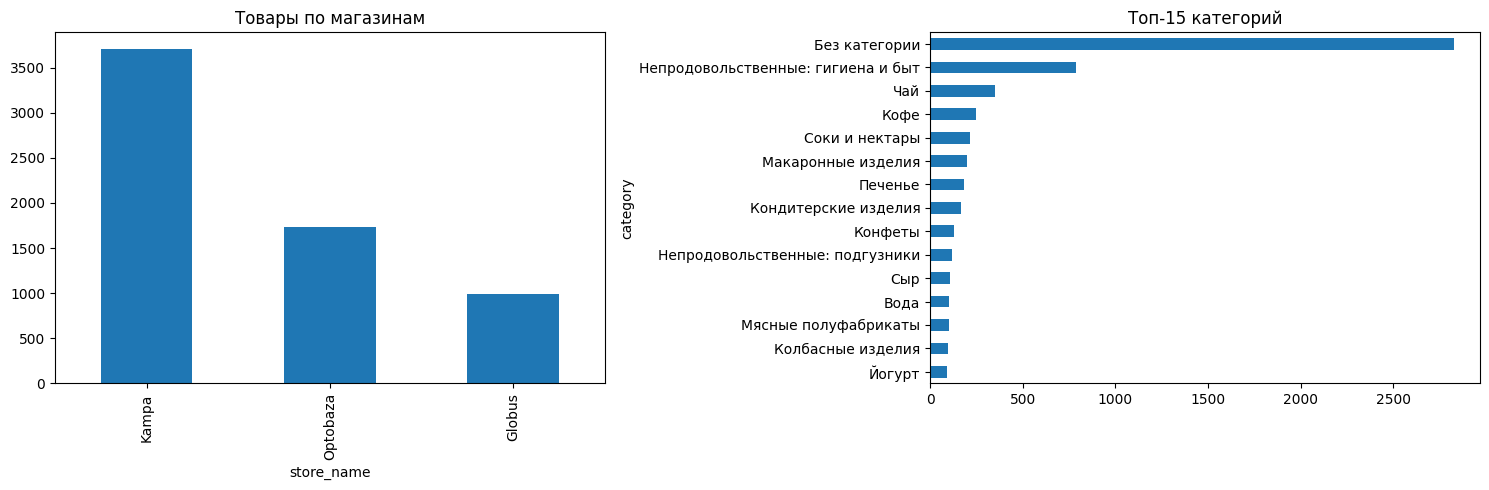

In [5]:
stores = products.groupby('store_name',dropna=False).size().sort_values(ascending=False)
categories = products.category.fillna('Без категории').value_counts()
display(stores.to_frame('products'));display(categories.head(25).to_frame('products'))
stores.to_csv(OUT/'stores.csv',header=['products'],encoding='utf-8-sig')
categories.to_csv(OUT/'categories.csv',header=['products'],encoding='utf-8-sig')
fig,axes=plt.subplots(1,2,figsize=(15,5))
stores.plot.bar(ax=axes[0],title='Товары по магазинам')
categories.head(15).sort_values().plot.barh(ax=axes[1],title='Топ-15 категорий')
plt.tight_layout();plt.savefig(OUT/'stores_categories.png',dpi=150);plt.show()


Цены
Анализируем только последнюю положительную цену 

,count,min,median,mean,max
store_name,,,,,
Globus,629,4.29,180.49,1722.96,35134.0
Kampa,2911,3.00,69.00,103.50,3750.0
Optobaza,1204,15.00,178.10,308.84,3430.0


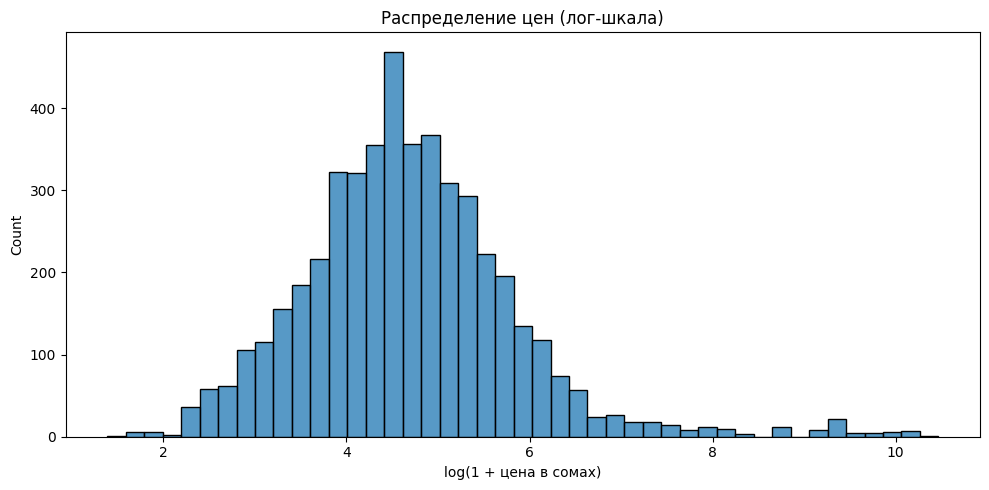

In [6]:
valid = df.loc[df.eligible_price.fillna(False).eq(True) & df.price_som.gt(0)].copy()
price_stats = valid.groupby('store_name',dropna=False).price_som.agg(['count','min','median','mean','max']).round(2)
display(price_stats);price_stats.to_csv(OUT/'price_stats.csv',encoding='utf-8-sig')
if len(valid):
    fig,ax=plt.subplots(figsize=(10,5))
    sns.histplot(np.log1p(valid.price_som),bins=45,ax=ax)
    ax.set(xlabel='log(1 + цена в сомах)',title='Распределение цен (лог-шкала)')
    plt.tight_layout();plt.savefig(OUT/'price_distribution.png',dpi=150);plt.show()


Выбросы методом IQR

In [7]:
unit = valid.loc[valid.price_per_unit.gt(0) & valid.category.notna() & valid.normalized_unit.notna()].copy()
if len(unit):
    stats = unit.groupby(['category','normalized_unit']).price_per_unit.agg(n='size',q1=lambda x:x.quantile(.25),q3=lambda x:x.quantile(.75)).reset_index()
    stats['iqr']=stats.q3-stats.q1
    stats['lower']=stats.q1-1.5*stats.iqr
    stats['upper']=stats.q3+1.5*stats.iqr
    checked=unit.merge(stats,on=['category','normalized_unit'],how='left',validate='many_to_one')
    outliers=checked.loc[(checked.n>=8)&(checked.iqr>0)&((checked.price_per_unit<checked.lower)|(checked.price_per_unit>checked.upper))]
else:
    outliers=unit.copy()
print('Кандидатов на проверку:',len(outliers))
display(outliers.head(30))
outliers.to_csv(OUT/'iqr_outliers.csv',index=False,encoding='utf-8-sig')


Кандидатов на проверку: 270


,product_id,store_id,original_name,name_clean,brand,category,total_quantity,normalized_unit,pack_count,attributes,...,collected_at,price_per_unit,eligible_price,source_status,n,q1,q3,iqr,lower,upper
1,2,1,Бифштекс рублен­ный Риха из говяди­ны 1кг 1 шт.,бифштекс рубленный риха из говядины 1кг 1 шт.,Риха,Мясные полуфабрикаты,1.00,кг,1,{'product_scope': 'food'},...,2026-11-06 15:22:35+00:00,852.00,True,public_page,89,230.0000,429.9800,199.9800,-69.97000,729.95000
3,4,1,Котле­ты Баркад 350 г 1 шт.,котлеты баркад 350 г 1 шт.,Баркад,Мясные полуфабрикаты,0.35,кг,1,{'product_scope': 'food'},...,2026-11-06 15:22:35+00:00,982.86,True,public_page,89,230.0000,429.9800,199.9800,-69.97000,729.95000
4,5,1,Фрика­дельки Баркад говяди­на 450гр GL 1 шт.,фрикадельки баркад говядина 450гр gl 1 шт.,Баркад,Мясные полуфабрикаты,0.45,кг,1,{'product_scope': 'food'},...,2026-11-06 15:22:35+00:00,1006.67,True,public_page,89,230.0000,429.9800,199.9800,-69.97000,729.95000
6,7,1,Нагет­сы Мираторг куриные с сыром 250г РЦ 1 шт.,нагетсы мираторг куриные с сыром 250г рц 1 шт.,Мираторг,Мясные полуфабрикаты,0.25,кг,1,{'product_scope': 'food'},...,2026-11-06 15:22:35+00:00,900.00,True,public_page,89,230.0000,429.9800,199.9800,-69.97000,729.95000
7,10,1,Котле­ты Дияр с говяди­ной 490г 1 шт.,котлеты дияр с говядиной 490г 1 шт.,Дияр,Мясные полуфабрикаты,0.49,кг,1,{'product_scope': 'food'},...,2026-11-06 15:22:35+00:00,1191.84,True,public_page,89,230.0000,429.9800,199.9800,-69.97000,729.95000
8,11,1,Фрика­дельки Дияр с говяди­ной 900г 1 шт.,фрикадельки дияр с говядиной 900г 1 шт.,Дияр,Мясные полуфабрикаты,0.90,кг,1,{'product_scope': 'food'},...,2026-11-06 15:22:35+00:00,1221.11,True,public_page,89,230.0000,429.9800,199.9800,-69.97000,729.95000
9,13,1,Фрика­дельки Аттила говяди­на 500г 1 шт.,фрикадельки аттила говядина 500г 1 шт.,Аттила,Мясные полуфабрикаты,0.50,кг,1,{'product_scope': 'food'},...,2026-11-06 15:22:35+00:00,1214.00,True,public_page,89,230.0000,429.9800,199.9800,-69.97000,729.95000
18,67,1,"Масло сливоч­ное Брест-Литовск 82,5% 120г 1 шт.",масло сливочное брест-литовск 82.5% 120г 1 шт.,None,Масло сливочное,0.12,кг,1,"{'fat_percent': '82.5', 'product_scope': 'food'}",...,2026-11-06 15:21:52+00:00,1362.25,True,public_page,27,294.4450,563.8900,269.4450,-109.72250,968.05750
19,68,1,"Масло сливоч­ное Брест-Литовск 72,5% 180г 1 шт.",масло сливочное брест-литовск 72.5% 180г 1 шт.,None,Масло сливочное,0.18,кг,1,"{'fat_percent': '72.5', 'product_scope': 'food'}",...,2026-11-06 15:21:52+00:00,1494.44,True,public_page,27,294.4450,563.8900,269.4450,-109.72250,968.05750
20,69,1,"Масло сливоч­ное Danke безлактз­ное 82,5 160г ...",масло сливочное danke безлактзное 82.5 160г 1 шт.,None,Масло сливочное,0.16,кг,1,{'product_scope': 'food'},...,2026-11-06 15:21:52+00:00,1500.00,True,public_page,27,294.4450,563.8900,269.4450,-109.72250,968.05750


Актуальность цен

In [8]:
freshness = valid.groupby('store_name',dropna=False).agg(latest_collection=('collected_at','max'),oldest_collection=('collected_at','min'),priced_products=('product_id','nunique'))
display(freshness)
freshness.to_csv(OUT/'price_freshness.csv',encoding='utf-8-sig')
if len(valid):
    daily=valid.assign(day=valid.collected_at.dt.date).groupby(['day','store_name'],dropna=False).size().unstack(fill_value=0)
    display(daily.tail(15));daily.to_csv(OUT/'latest_price_dates.csv',encoding='utf-8-sig')


,latest_collection,oldest_collection,priced_products
store_name,,,
Globus,2026-11-06 15:24:01+00:00,2026-11-06 15:17:42+00:00,629
Kampa,2026-11-06 16:13:39+00:00,2026-11-04 09:53:13+00:00,2911
Optobaza,2026-11-06 15:38:00+00:00,2026-11-04 09:38:23+00:00,1204


store_name,Globus,Kampa,Optobaza
day,,,
2026-11-04,0,269,8
2026-11-06,629,2642,1196


В итоге сохраняем отчеты eda_results

In [9]:
print('EDA завершён. Файлы:', *sorted(p.name for p in OUT.iterdir()), sep='\n- ')

EDA завершён. Файлы:
- categories.csv
- iqr_outliers.csv
- latest_price_dates.csv
- missing.csv
- price_distribution.png
- price_freshness.csv
- price_stats.csv
- quality_by_store.csv
- stores.csv
- stores_categories.png
- summary.csv
